# Decision tree for loan default (baseline)

The group's mandatory baseline model, trained on the shared split from [03_feature_engineering.ipynb](03_feature_engineering.ipynb). Tree size and the threshold are chosen by cross-validation on the training set; the test set is used once.

## 1. Load the shared training and test data

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import (
    accuracy_score, auc, brier_score_loss, confusion_matrix, f1_score,
    log_loss, precision_recall_curve, precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict
from sklearn.tree import DecisionTreeClassifier, plot_tree

ROOT = next(
    (folder for folder in (Path.cwd(), *Path.cwd().parents)
     if (folder / 'data' / 'financial_loan_dataset_v2.csv').is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError('Open the notebook from the project folder or its notebooks directory.')
RESULTS_DIR = ROOT / 'results'
TARGET = 'loan_default'
SEED = 42

train_df = pd.read_csv(ROOT / 'data' / 'train.csv')
test_df = pd.read_csv(ROOT / 'data' / 'test.csv')
y_train, y_test = train_df[TARGET], test_df[TARGET]
print(f'Train: {len(y_train):,} rows | Test: {len(y_test):,} rows | Default rate: {y_train.mean():.1%}')

Train: 960 rows | Test: 240 rows | Default rate: 20.6%


## 2. Define the feature sets

The `decision_tree_and_random_forest` set from notebook 03. The tabular-only set drops the two Qwen3.5 scores to measure what the text features add.

In [2]:
qwen_cols = ['slm_sentiment_score', 'slm_strain_score']
tabular_cols = [
    'age', 'annual_income', 'credit_score', 'credit_score_tier', 'loan_amount',
    'debt_to_income_ratio', 'late_payments_12m', 'account_tenure_months',
    'loan_to_income_ratio', 'total_burden_ratio', 'residual_monthly_income',
    'late_payment_intensity', 'has_late_payments', 'chronic_delinquency_flag',
    'credit_utilization_stress', 'employment_stability_score',
]
dt_cols = tabular_cols + qwen_cols

## 3. Tune the tree with cross-validation

An unrestricted tree memorises the training data, so depth, minimum leaf size and split criterion are tuned by 5-fold ROC AUC. The threshold maximises macro F1 on out-of-fold training predictions, the same rule as the other 04 notebooks.

In [3]:
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
param_grid = {
    'max_depth': [2, 3, 4, 5, 6, 8, 10],
    'min_samples_leaf': [1, 5, 10, 20, 40, 60],
    'criterion': ['gini', 'entropy'],
}
search = GridSearchCV(
    DecisionTreeClassifier(random_state=SEED), param_grid, scoring='roc_auc', cv=folds,
).fit(train_df[dt_cols], y_train)
best_params = search.best_params_
print('Best parameters:', best_params, f'| CV ROC AUC: {search.best_score_:.4f}')

oof_probabilities = cross_val_predict(
    DecisionTreeClassifier(random_state=SEED, **best_params), train_df[dt_cols], y_train,
    cv=folds, method='predict_proba',
)[:, 1]
thresholds = np.arange(5, 96) / 100
oof_scores = [f1_score(y_train, oof_probabilities >= t, average='macro') for t in thresholds]
tuned_threshold = thresholds[int(np.argmax(oof_scores))]
print(f'Training-selected threshold: {tuned_threshold:.2f}')

Best parameters: {'criterion': 'gini', 'max_depth': 4, 'min_samples_leaf': 40} | CV ROC AUC: 0.7916


Training-selected threshold: 0.40


## 4. Evaluate on the held-out test set

Same metric columns as the other 04 notebooks, so 05_evaluation can stack the results.

In [4]:
def evaluate_predictions(name, y_true, probabilities, threshold=0.50):
    predicted = probabilities >= threshold
    tn, fp, fn, tp = confusion_matrix(y_true, predicted, labels=[0, 1]).ravel()
    precision, recall, _ = precision_recall_curve(y_true, probabilities)
    return {
        'Model': name,
        'Threshold': threshold,
        'Accuracy': accuracy_score(y_true, predicted),
        'Precision': precision_score(y_true, predicted, zero_division=0),
        'Recall': recall_score(y_true, predicted),
        'Specificity': tn / (tn + fp),
        'F1_Score': f1_score(y_true, predicted),
        'Macro_F1': f1_score(y_true, predicted, average='macro'),
        'ROC_AUC': roc_auc_score(y_true, probabilities),
        'PR_AUC': auc(recall, precision),
        'Brier_Score': brier_score_loss(y_true, probabilities),
        'Log_Loss': log_loss(y_true, probabilities),
        'TP': tp, 'TN': tn, 'FP': fp, 'FN': fn,
    }


def fit_and_predict(features, params):
    model = DecisionTreeClassifier(random_state=SEED, **params).fit(train_df[features], y_train)
    return model, model.predict_proba(test_df[features])[:, 1]


full_tree, full_probabilities = fit_and_predict(dt_cols, {})
_, tabular_probabilities = fit_and_predict(tabular_cols, best_params)
final_model, final_probabilities = fit_and_predict(dt_cols, best_params)
print(f'Unrestricted tree: depth {full_tree.get_depth()}, {full_tree.get_n_leaves()} leaves | '
      f'Tuned tree: depth {final_model.get_depth()}, {final_model.get_n_leaves()} leaves')

metrics = pd.DataFrame([
    evaluate_predictions('1. Decision tree, unrestricted + Qwen', y_test, full_probabilities),
    evaluate_predictions('2. Decision tree tuned, tabular only', y_test, tabular_probabilities),
    evaluate_predictions('3. Decision tree tuned + Qwen non-thinking', y_test, final_probabilities),
    evaluate_predictions('4. Decision tree tuned + Qwen non-thinking, tuned threshold',
                         y_test, final_probabilities, tuned_threshold),
])
RESULTS_DIR.mkdir(exist_ok=True)
metrics.to_csv(RESULTS_DIR / 'decision_tree_metrics.csv', index=False)
display(metrics.set_index('Model').round(4))

Unrestricted tree: depth 16, 131 leaves | Tuned tree: depth 4, 10 leaves


,Threshold,Accuracy,Precision,Recall,Specificity,F1_Score,Macro_F1,ROC_AUC,PR_AUC,Brier_Score,Log_Loss,TP,TN,FP,FN
Model,,,,,,,,,,,,,,,
"1. Decision tree, unrestricted + Qwen",0.5,0.7417,0.3750,0.36,0.8421,0.3673,0.6025,0.6011,0.4342,0.2583,9.3113,18,160,30,32
"2. Decision tree tuned, tabular only",0.5,0.8042,0.6364,0.14,0.9789,0.2295,0.5587,0.7702,0.4792,0.1410,0.4403,7,186,4,43
3. Decision tree tuned + Qwen non-thinking,0.5,0.8042,0.6364,0.14,0.9789,0.2295,0.5587,0.7441,0.4727,0.1431,0.4568,7,186,4,43
"4. Decision tree tuned + Qwen non-thinking, tuned threshold",0.4,0.8000,0.5333,0.32,0.9263,0.4000,0.6400,0.7441,0.4727,0.1431,0.4568,16,176,14,34


## 5. Final tree and feature importance

Each box shows the split rule, the share of training borrowers, and the class proportions [no default, default]; blue boxes predict default.

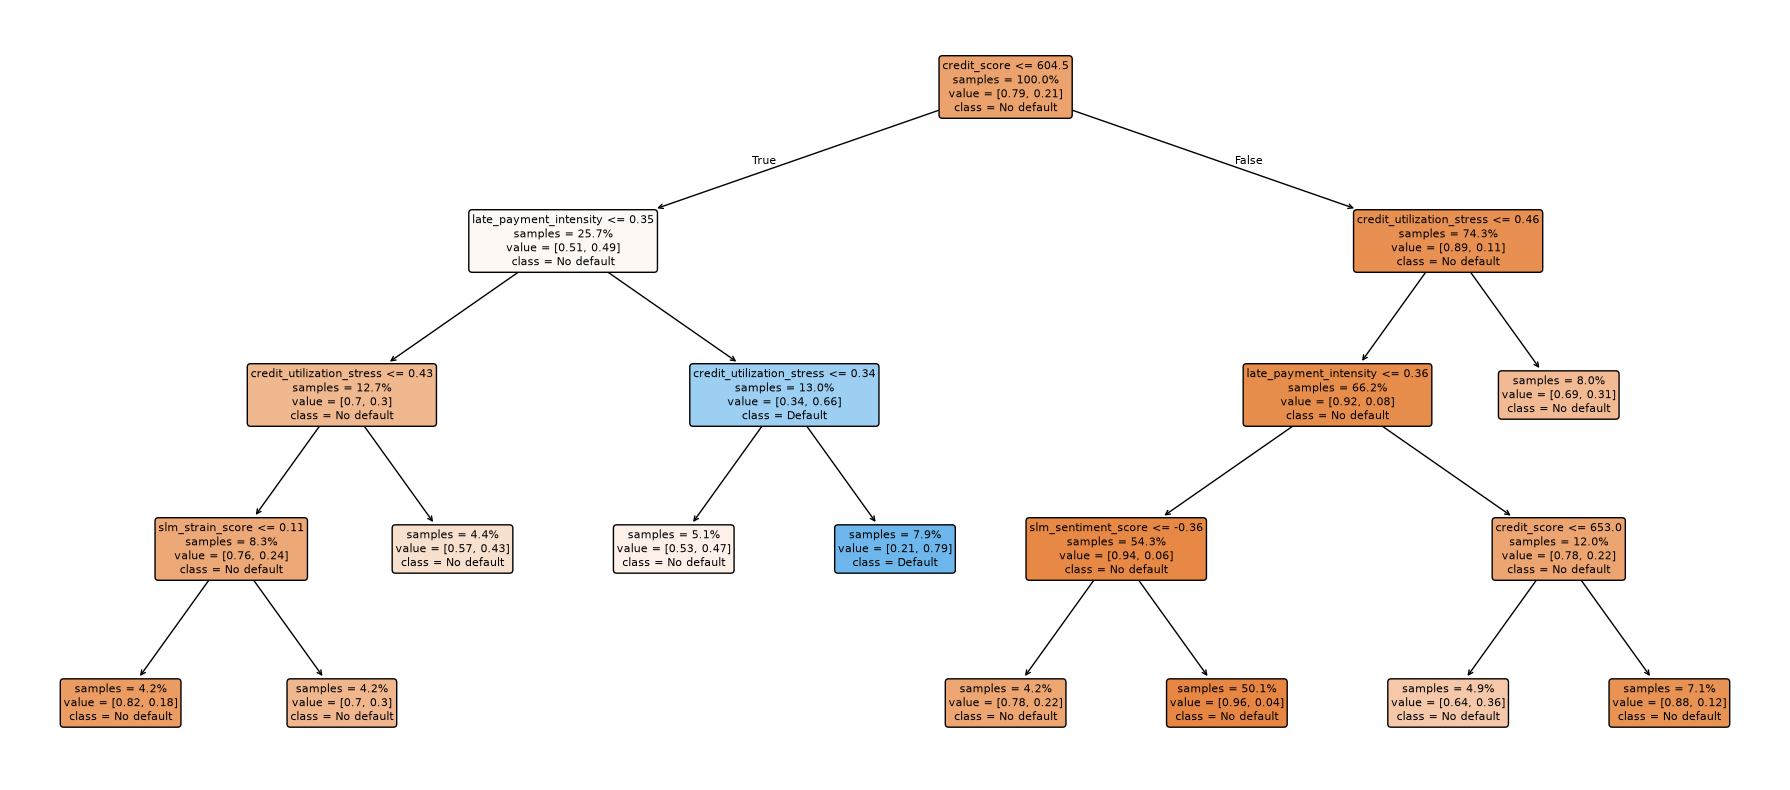

,Importance
Feature,
credit_score,0.585
late_payment_intensity,0.222
credit_utilization_stress,0.160
slm_sentiment_score,0.026
slm_strain_score,0.007


In [5]:
fig, ax = plt.subplots(figsize=(18, 8))
plot_tree(
    final_model, feature_names=dt_cols, class_names=['No default', 'Default'],
    filled=True, rounded=True, impurity=False, proportion=True, precision=2,
    fontsize=8, ax=ax,
)
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'decision_tree_final_tree.png', dpi=200)
plt.show()

importance = pd.Series(final_model.feature_importances_, index=dt_cols, name='Importance')
importance = importance.sort_values(ascending=False).rename_axis('Feature')
importance.to_frame().to_csv(RESULTS_DIR / 'decision_tree_feature_importance.csv')
display(importance[importance > 0].round(3).to_frame())

## 6. Key findings

- **Tuning stops overfitting.** The unrestricted tree (depth 16, 131 leaves) scores test ROC AUC 0.60; the tuned tree (depth 4, at least 40 borrowers per leaf) scores 0.744. As the baseline it trails XGBoost (0.794) and logistic regression (about 0.81).
- **The threshold matters.** Lowering it from 0.50 to 0.40 catches 16 of 50 defaulters instead of 7 (recall 14% to 32%), at the cost of 10 more false alarms.
- **Credit history drives the tree; the Qwen scores add nothing.** Credit score, late-payment intensity and credit utilisation stress make up 97% of importance, and the tabular-only tree scores slightly higher (0.770). The riskiest leaf (79% default) is credit score ≤ 604.5 with high late-payment intensity and utilisation stress.